# Model Training & Analysis

Trains the final LightGBM model using the tuned hyperparameters, evaluates it,
and registers it with MLflow.

**Pipeline overview**
1. Load `model_dataset.parquet` & tuned hyperparameters
2. Train/validation split (identical to Notebook 2 — same `RANDOM_STATE`/`TEST_SIZE`)
3. Train the final model with early stopping
4. Find the optimal classification threshold (F1-maximizing)
5. Compute & export evaluation metrics
6. Feature importance analysis
7. ROC & Precision-Recall curves
8. MLflow tracking & model registration

**Outputs:**
- `data/ModelOutput/classification_report_optimal_threshold.{txt,csv}`
- `data/ModelOutput/lgbm_feature_importance.xlsx`
- `data/ModelOutput/model_evaluation_curves.png`
- MLflow run + registered model `HomeCredit_Scorecard_Model`

## 1. Imports & Configuration

In [ ]:
import os
import json
import pandas as pd
import numpy as np
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, roc_auc_score, log_loss,
    precision_score, recall_score, f1_score,
    precision_recall_curve, classification_report,
    roc_curve, auc,
)
PROJECT_ROOT = os.environ.get("HOMECREDIT_PROJECT_ROOT", r"a:\Dominic\My Projects\Home Credit")
DATA_ROOT = os.environ.get("HOMECREDIT_DATA_ROOT", r"a:\Dominic\My Projects\Home Credit\data")
SRC_ROOT  = os.environ.get("HOMECREDIT_SRC_DIR", r"a:\Dominic\My Projects\Home Credit\src")

MDS_DIR = os.path.join(DATA_ROOT, "ModelDataset")
HPO_DIR = os.path.join(DATA_ROOT, "HyperParameters")
VAR_SELECTION_DIR = os.path.join(DATA_ROOT, "Variable-Selection")

PATH_MODEL_DATASET = os.path.join(MDS_DIR, "model_dataset_final.parquet")
PATH_BEST_HYPERPARS = os.path.join(HPO_DIR, "LightGBM_v1", "lgbm_resolved_best.json")
# use v1 feature importance table to select features for v2 model training
PATH_FEATURE_IMPORTANCE = os.path.join(DATA_ROOT, "ModelOutput", "LightGBM_v1")
PATH_SELECTED_FEATURES = os.path.join(VAR_SELECTION_DIR, "numeric_selection_metrics_full_df.xlsx")

MODEL_OUTPUT_DIR = os.path.join(DATA_ROOT, "ModelOutput", "LightGBM_v2")
os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

# ── MUST match Notebook 2 exactly — same split = comparable AUC/metrics ──────
RANDOM_STATE = 1994
TEST_SIZE    = 0.20

# ── MLflow toggle ─────────────────────────────────────────────────────────
ENABLE_MLFLOW = True
MLFLOW_TRACKING_URI = f"file:{DATA_ROOT}/mlruns".replace('\\', '/')
MLFLOW_EXPERIMENT_NAME = "Home_Credit_Default_Risk"
MLFLOW_REGISTERED_MODEL_NAME = "HomeCredit_Scorecard_Model"

## 2. Load Data & Tuned Hyperparameters

> **Note:** uses all features where `cumulative importance <= 80%` from first model (v1).

In [2]:
model_dataset = pd.read_parquet(PATH_MODEL_DATASET)
importance_df = pd.read_excel(os.path.join(PATH_FEATURE_IMPORTANCE, 'lgbm_feature_importance.xlsx'))

importance_df = importance_df.sort_values(by='importance', ascending=False)
feature_cols = importance_df[importance_df['cumulative_importance'] <= 0.8]['feature'].tolist()
print(f"Selected {len(feature_cols)} features for model training (cumulative importance <= 0.8)")

X = model_dataset[['SK_ID_CURR'] + feature_cols]
y = model_dataset['TARGET']
X.set_index('SK_ID_CURR', inplace=True)

with open(PATH_BEST_HYPERPARS) as f:
    resolved_best = json.load(f)

print("Loaded hyperparameters:")
print(json.dumps(resolved_best, indent=2))

Selected 58 features for model training (cumulative importance <= 0.8)
Loaded hyperparameters:
{
  "colsample_bytree": 0.21807117503284643,
  "learning_rate": 0.027563061296715565,
  "max_depth": 9,
  "min_child_samples": 500,
  "min_split_gain ": 0.03885695338663592,
  "n_estimators": 680,
  "num_leaves": 113,
  "reg_alpha": 2.4526747630907937,
  "reg_lambda": 0.46307761596584635
}


In [3]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f"X_train: {X_train.shape}  |  X_val: {X_val.shape}")

X_train: (246008, 58)  |  X_val: (61503, 58)


## 3. Train the Final Model

In [4]:
final_model = lgb.LGBMClassifier(
    objective='binary',
    boosting_type='goss',
    seed=42,
    verbose=-1,
    **resolved_best,
)

print("Training the final optimized model...")
final_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=True)],
)

# This is THE probability array used for every probability-based metric below.
# It is never overwritten — see Section 5 for why that matters.
y_val_proba = final_model.predict_proba(X_val)[:, 1]
val_auc = roc_auc_score(y_val, y_val_proba)
print(f"\nValidation AUC: {val_auc:.4f}")

Training the final optimized model...
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[672]	valid_0's binary_logloss: 0.241844

Validation AUC: 0.7713


Export the validation samplefor determining scoring parameters.

In [5]:
test_df = pd.DataFrame({
    'SK_ID_CURR': X_val.index,
    'TARGET': y_val,
    'predicted_proba': y_val_proba
})
test_df.to_parquet(os.path.join(MODEL_OUTPUT_DIR, "test_predictions.parquet"), index=True)

train_df = pd.DataFrame({
    'SK_ID_CURR': X_train.index,
    'TARGET': y_train,
    'predicted_proba': final_model.predict_proba(X_train)[:, 1]
})

train_df.to_parquet(os.path.join(MODEL_OUTPUT_DIR, "train_predictions.parquet"), index=True)

## 4. Find the Optimal Classification Threshold

Finds the probability threshold that maximizes F1-score on the validation set,
using `y_val_proba` (continuous probabilities).

In [74]:
precision, recall, thresholds = precision_recall_curve(y_val, y_val_proba)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

best_f1_idx    = np.argmax(f1_scores)
best_threshold = thresholds[best_f1_idx]
best_f1_score  = f1_scores[best_f1_idx]

print(f"Best threshold found : {best_threshold:.4f}")
print(f"F1-score at threshold: {best_f1_score:.4f}\n")

y_val_pred = (y_val_proba >= best_threshold).astype(int)

print(f"--- Performance at Optimal Threshold ({best_threshold:.2f}) ---")
print(classification_report(y_val, y_val_pred))

Best threshold found : 0.1629
F1-score at threshold: 0.3293

--- Performance at Optimal Threshold (0.16) ---
              precision    recall  f1-score   support

           0       0.95      0.90      0.92     56538
           1       0.27      0.43      0.33      4965

    accuracy                           0.86     61503
   macro avg       0.61      0.66      0.63     61503
weighted avg       0.89      0.86      0.87     61503



## 5. Evaluation Metrics

> **Critical fix (Bug 9 & 10 in the original):** the original notebook reused the
> variable name `y_pred_proba` for both the continuous probability array *and* the
> thresholded binary prediction. By the time the ROC/PR curves and `roc_auc_score`/
> `log_loss` were computed, `y_pred_proba` had been silently overwritten with the
> binary 0/1 array — producing a degenerate 3-point ROC curve and an incorrect AUC
> that didn't match the model's actual discrimination ability. This notebook keeps
> two clearly distinct variables throughout: `y_val_proba` (continuous, for
> AUC/log-loss/ROC/PR) and `y_val_pred` (binary, for precision/recall/F1/accuracy).
> They are never reassigned after this point.

In [75]:
report_text = classification_report(y_val, y_val_pred)
with open(os.path.join(MODEL_OUTPUT_DIR, 'classification_report_optimal_threshold.txt'), 'w', encoding='utf-8') as f:
    f.write(report_text)

report_dict = classification_report(y_val, y_val_pred, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(os.path.join(MODEL_OUTPUT_DIR, 'classification_report_optimal_threshold.csv'), index=True)

print("Saved classification report (.txt and .csv).")

Saved classification report (.txt and .csv).


In [76]:
# FIX: AUC and log-loss use y_val_proba (continuous); precision/recall/F1/accuracy
# use y_val_pred (thresholded binary). Neither variable is reassigned elsewhere.
print(f"Accuracy : {accuracy_score(y_val, y_val_pred):.4f}  (can be misleading on imbalanced data)\n")

print(f"AUC Score: {roc_auc_score(y_val, y_val_proba):.4f}")
print(f"Log Loss : {log_loss(y_val, y_val_proba):.4f}\n")

print(f"Precision: {precision_score(y_val, y_val_pred):.4f}")
print(f"Recall   : {recall_score(y_val, y_val_pred):.4f}")
print(f"F1-Score : {f1_score(y_val, y_val_pred):.4f}")

Accuracy : 0.8590  (can be misleading on imbalanced data)

AUC Score: 0.7713
Log Loss : 0.2418

Precision: 0.2673
Recall   : 0.4288
F1-Score : 0.3293


## 6. Feature Importance

In [77]:
importance_df = pd.DataFrame({
    'feature': final_model.feature_name_,
    'importance': final_model.feature_importances_,
}).sort_values(by='importance', ascending=False).reset_index(drop=True)

importance_df['percentage'] = importance_df['importance'] / importance_df['importance'].sum()
importance_df['cumulative_importance'] = importance_df['percentage'].cumsum()

significant_features_95 = importance_df.loc[
    importance_df['cumulative_importance'] <= 0.95, 'feature'
].tolist()
significant_features_90 = importance_df.loc[
    importance_df['cumulative_importance'] <= 0.90, 'feature'
].tolist()
significant_features_80 = importance_df.loc[
    importance_df['cumulative_importance'] <= 0.80, 'feature'
].tolist()

print(f"Original features                       : {len(final_model.feature_name_)}")
print(f"Features needed to reach 95% importance : {len(significant_features_95)}")
print(f"Features needed to reach 90% importance : {len(significant_features_90)}")
print(f"Features needed to reach 80% importance : {len(significant_features_80)}")

# Join with variable selection metrics to get a full picture of feature importance and selection criteria
selection_metrics_df = pd.read_excel(PATH_SELECTED_FEATURES)
importance_df = importance_df.merge(selection_metrics_df, how='left', left_on='feature', right_on='variable')

importance_df.to_excel(os.path.join(MODEL_OUTPUT_DIR, 'lgbm_feature_importance.xlsx'), index=False)
print("Saved feature importance table.")

Original features                       : 58
Features needed to reach 95% importance : 48
Features needed to reach 90% importance : 42
Features needed to reach 80% importance : 33
Saved feature importance table.


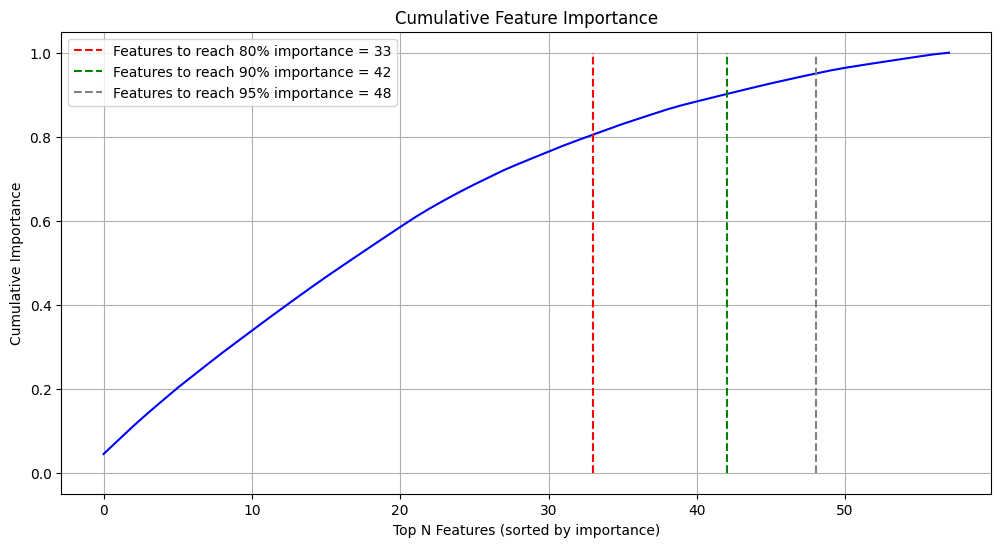

In [78]:
plt.figure(figsize=(12, 6))
plt.plot(importance_df['cumulative_importance'].sort_values(ascending=False), color='blue')
plt.title("Cumulative Feature Importance")
plt.xlabel("Top N Features (sorted by importance)")
plt.ylabel("Cumulative Importance")
plt.vlines(x = len(significant_features_80), ymin=0, ymax=1, linestyle='--', color='red', label=f'Features to reach 80% importance = {len(significant_features_80)}')
plt.vlines(x = len(significant_features_90), ymin=0, ymax=1, linestyle='--', color='green', label=f'Features to reach 90% importance = {len(significant_features_90)}')
plt.vlines(x = len(significant_features_95), ymin=0, ymax=1, linestyle='--', color='grey', label=f'Features to reach 95% importance = {len(significant_features_95)}')
plt.legend(loc='upper left')
plt.grid()
plt.show()

## 7. Discrimination and Calibration Check

### 7.a ROC & Precision-Recall Curves

Both curves use `y_val_proba` (continuous probabilities) — this is what makes a
smooth curve possible; plotting against binary predictions (the original's bug)
collapses the curve to 3 points.

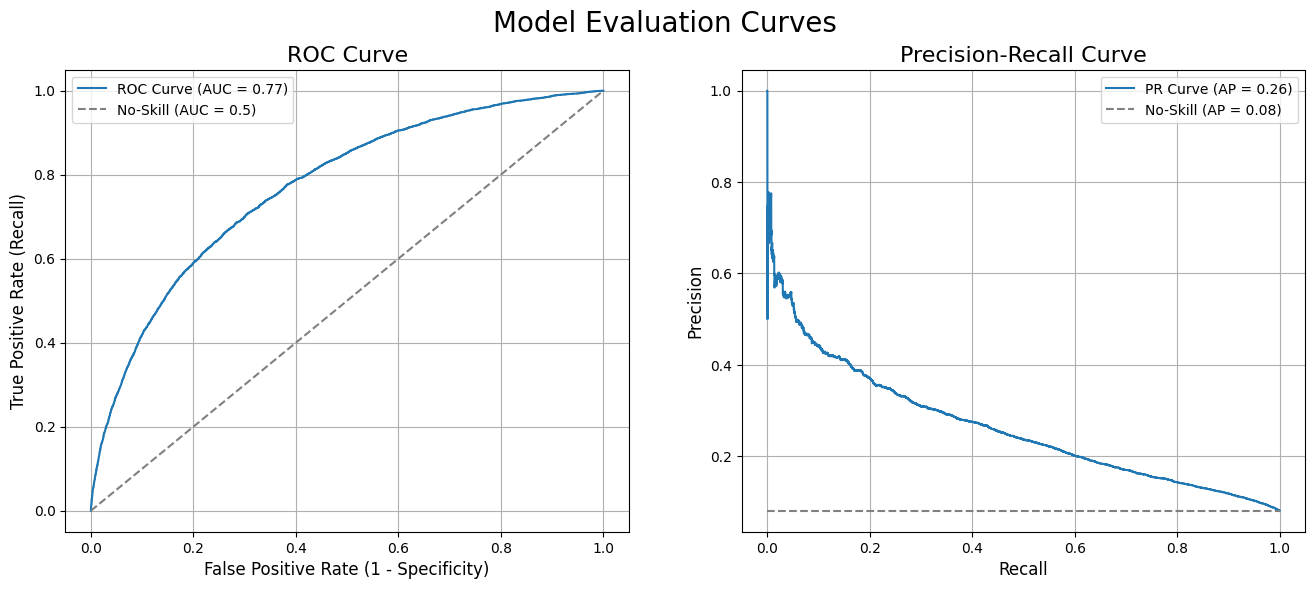

Saved evaluation curves.


In [79]:
fpr, tpr, _ = roc_curve(y_val, y_val_proba)
roc_auc_value = roc_auc_score(y_val, y_val_proba)

pr_precision, pr_recall, _ = precision_recall_curve(y_val, y_val_proba)
pr_auc_value = auc(pr_recall, pr_precision)

fig_roc, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc_value:.2f})')
ax1.plot([0, 1], [0, 1], linestyle='--', color='gray', label='No-Skill (AUC = 0.5)')
ax1.set_title('ROC Curve', fontsize=16)
ax1.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
ax1.set_ylabel('True Positive Rate (Recall)', fontsize=12)
ax1.legend(); ax1.grid(True)

ax2.plot(pr_recall, pr_precision, label=f'PR Curve (AP = {pr_auc_value:.2f})')
no_skill = (y_val == 1).mean()
ax2.plot([0, 1], [no_skill, no_skill], linestyle='--', color='gray', label=f'No-Skill (AP = {no_skill:.2f})')
ax2.set_title('Precision-Recall Curve', fontsize=16)
ax2.set_xlabel('Recall', fontsize=12)
ax2.set_ylabel('Precision', fontsize=12)
ax2.legend(); ax2.grid(True)

fig_roc.suptitle('Model Evaluation Curves', fontsize=20)
fig_roc.savefig(os.path.join(MODEL_OUTPUT_DIR, 'model_evaluation_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

print("Saved evaluation curves.")

### 7.b Calibration Curves

A calibration curve (or reliability diagram) is a visual tool that checks if your model's predicted probabilities match reality. If a model predicts a 70% chance of a default happening, approximately 70% of those cases should actually happen. How its plotted:
- **X-axis**: The predicted probabilities grouped into "buckets" (e.g., all cases where the model predicted 0.6 to 0.7).
- **Y-axis**: The actual fraction of positive events that occurred in those buckets.
- **Diagonal Line**: The perfect calibration line (often y=x), where predicted probabilities exactly equal observed frequencies. If the model predicts a 20% chance of default, exactly 20% of the people in that bucket actually default.
- **The Colored Line**: This is your actual model. If the line drops below the gray dashed line, your model is over-predicting risk (predicting more defaults than actually happen). If it goes above the gray line, it is under-predicting risk.


However, it is not always perfect. If the data is highly imbalanced or the model does not perfectly fit the data, the calibration curve might bend away from the diagonal line.


> **Uniform binning** divides the probability spectrum into 10 perfectly equal widths: 0-10%, 10-20%, 20-30%, all the way up to 90-100%. Uniform binning then plots a dot for those 3 applicants all the way up at the top right of the chart.

> **Quantile binning** does not care about the 0-100% spectrum. It forces exactly 10% of your total applicant volume into each of the 10 buckets. If you have 10,000 applicants, every single dot on that chart represents exactly 1,000 people. 

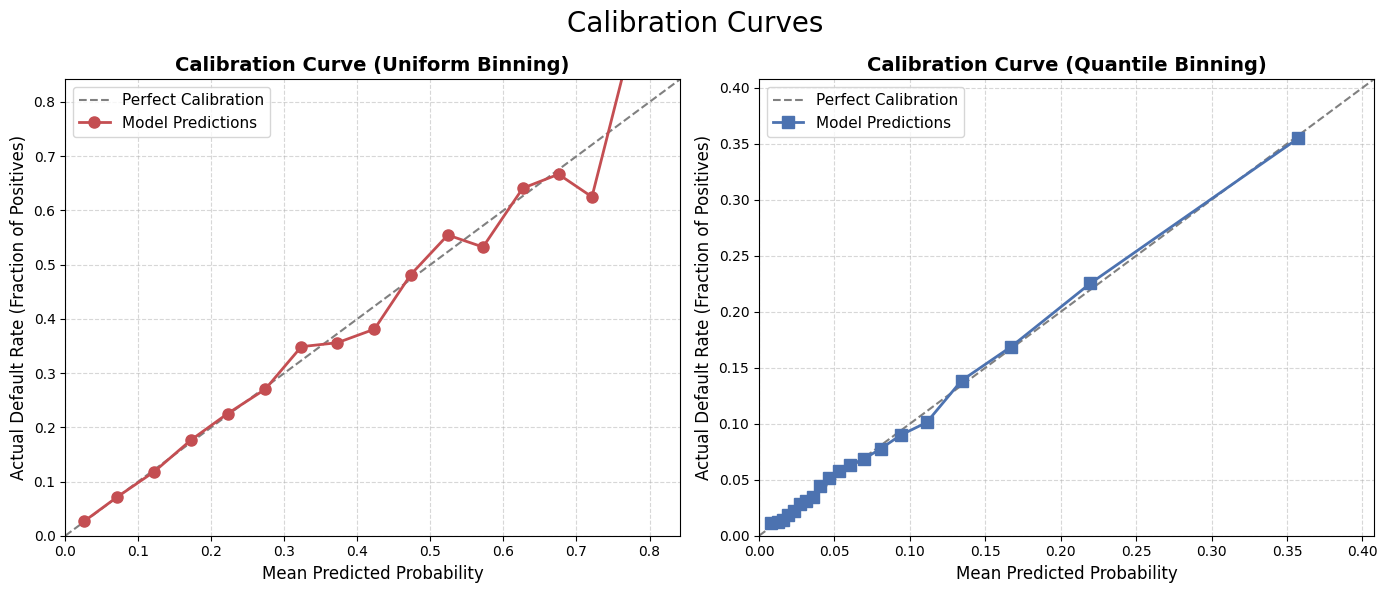

In [80]:
from sklearn.calibration import calibration_curve

# Number of bins to divide the probabilities into
N_BINS = 20

# Calculate Calibration Curves using scikit-learn

# Strategy 1: Uniform (Equal-width probability ranges, e.g., 0-10%, 10-20%)
prob_true_uni, prob_pred_uni = calibration_curve(
    y_val, y_val_proba, n_bins=N_BINS, strategy='uniform'
)

# Strategy 2: Quantile (Equal number of applicants in each bin)
prob_true_quant, prob_pred_quant = calibration_curve(
    y_val, y_val_proba, n_bins=N_BINS, strategy='quantile'
)
# ==============================================================================
# 2. PLOTTING THE CHARTS
# ==============================================================================
fig_cal, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- Plot 1: Uniform Binning ---
ax1.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')
ax1.plot(prob_pred_uni, prob_true_uni, marker='o', color='#C44E52', 
         linewidth=2, markersize=8, label='Model Predictions')

ax1.set_title('Calibration Curve (Uniform Binning)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Mean Predicted Probability', fontsize=12)
ax1.set_ylabel('Actual Default Rate (Fraction of Positives)', fontsize=12)
ax1.set_xlim([0.0, max(prob_pred_uni)+0.05])
ax1.set_ylim([0.0, max(prob_pred_uni)+0.05])
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left', fontsize=11)

# --- Plot 2: Quantile Binning ---
ax2.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')
ax2.plot(prob_pred_quant, prob_true_quant, marker='s', color='#4C72B0', 
         linewidth=2, markersize=8, label='Model Predictions')

ax2.set_title('Calibration Curve (Quantile Binning)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Mean Predicted Probability', fontsize=12)
ax2.set_ylabel('Actual Default Rate (Fraction of Positives)', fontsize=12)
ax2.set_xlim([0.0, max(prob_pred_quant)+0.05])
ax2.set_ylim([0.0, max(prob_pred_quant)+0.05])
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper left', fontsize=11)
fig_cal.suptitle('Calibration Curves', fontsize=20)
plt.tight_layout()
plt.show()

fig_cal.savefig(os.path.join(MODEL_OUTPUT_DIR, 'calibration_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

In [81]:
def ece_from_binned_table(df, volume_col, pred_pd_col, actual_rate_col):
    """
    Calculates Expected Calibration Error (ECE) directly from a binned summary DataFrame.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        The aggregated binned table.
    volume_col : str
        Column name for total applicants/volume in each bin (e.g., 'Total_Applicants').
    pred_pd_col : str
        Column name for the mean predicted probability in each bin (e.g., 'Average_PD').
    actual_rate_col : str
        Column name for the actual default rate in each bin (e.g., 'Actual_Default_Rate').
    """
    # 1. Total number of applicants across the entire portfolio
    total_volume = df[volume_col].sum()
    
    # 2. Calculate the absolute difference between predicted PD and actual default rate for each bin
    abs_bin_error = (df[pred_pd_col] - df[actual_rate_col]).abs()
    
    # 3. Weight each bin's error by its proportion of total portfolio volume
    weighted_bin_error = (df[volume_col] / total_volume) * abs_bin_error
    
    # 4. Sum up the weighted errors to get final ECE
    ece = weighted_bin_error.sum()
    
    return ece

In [82]:
# ==============================================================================
# 1. QUANTILE BINNING TABLE (Equal Volume - The Industry Standard)
# ==============================================================================

dist_df = pd.DataFrame({
    'Probability': y_val_proba,
    'Actual_Default': y_val.values 
})
# 1. Create Quantile Bins
dist_df['Quantile_Bin'] = pd.qcut(dist_df['Probability'], q=20, duplicates='drop')

quantile_table = dist_df.groupby('Quantile_Bin').agg(
    Total_Applicants=('Probability', 'count'),
    Defaults=('Actual_Default', 'sum'),
    Average_PD=('Probability', 'mean'),
    Actual_Default_Rate=('Actual_Default', 'mean')
).reset_index()
quantile_table['Expected_Defaults'] = (quantile_table['Total_Applicants'] * quantile_table['Average_PD']).round(2)

print("=== QUANTILE BINNING (Equal Volume) ===")
display_table = quantile_table.copy()
# Format as percentages for clean reading
display_table['Average_PD'] = (display_table['Average_PD'] * 100).round(2).astype(str) + '%'
display_table['Actual_Default_Rate'] = (display_table['Actual_Default_Rate'] * 100).round(2).astype(str) + '%'
print(display_table.to_string(index=False))

quantile_table.to_excel(os.path.join(MODEL_OUTPUT_DIR, 'quantile_binning_table.xlsx'), index=False)

print("\n" + "="*50)
ece = ece_from_binned_table(quantile_table, 'Total_Applicants', 'Average_PD', 'Actual_Default_Rate')
print(f"Expected Calibration Error (ECE): {ece:.4f}")
print("\n" + "="*50)

=== QUANTILE BINNING (Equal Volume) ===
     Quantile_Bin  Total_Applicants  Defaults Average_PD Actual_Default_Rate  Expected_Defaults
(0.00084, 0.0104]              3076        34      0.77%               1.11%              23.79
 (0.0104, 0.0143]              3075        39      1.24%               1.27%              38.13
 (0.0143, 0.0177]              3075        44       1.6%               1.43%              49.19
 (0.0177, 0.0212]              3075        58      1.94%               1.89%              59.81
 (0.0212, 0.0248]              3075        67       2.3%               2.18%              70.79
 (0.0248, 0.0288]              3075        86      2.68%                2.8%              82.47
 (0.0288, 0.0332]              3075        96      3.09%               3.12%              95.16
  (0.0332, 0.038]              3075       105      3.56%               3.41%             109.39
  (0.038, 0.0435]              3075       137      4.07%               4.46%             125.02


C:\Users\domjo\AppData\Local\Temp\ipykernel_33232\2331405535.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  quantile_table = dist_df.groupby('Quantile_Bin').agg(


In [83]:
# ==============================================================================
# 2. UNIFORM BINNING TABLE (Equal Width - The Illusion)
# ==============================================================================
dist_df['Uniform_Bin'] = pd.cut(dist_df['Probability'], bins=np.linspace(0, 1, 21))

uniform_table = dist_df.groupby('Uniform_Bin', observed=False).agg(
    Total_Applicants=('Probability', 'count'),
    Defaults=('Actual_Default', 'sum'),
    Average_PD=('Probability', 'mean'),
    Actual_Default_Rate=('Actual_Default', 'mean')
).reset_index()

# Format as percentages
uniform_table['Average_PD'] = (uniform_table['Average_PD'] * 100).round(2).astype(str) + '%'
uniform_table['Actual_Default_Rate'] = (uniform_table['Actual_Default_Rate'] * 100).round(2).astype(str) + '%'

print("\n\n=== UNIFORM BINNING (Equal Width) ===")
print(uniform_table.to_string(index=False))

uniform_table.to_excel(os.path.join(MODEL_OUTPUT_DIR, 'uniform_binning_table.xlsx'), index=False)



=== UNIFORM BINNING (Equal Width) ===
Uniform_Bin  Total_Applicants  Defaults Average_PD Actual_Default_Rate
(0.0, 0.05]             30915       829       2.6%               2.68%
(0.05, 0.1]             14877      1064      7.12%               7.15%
(0.1, 0.15]              6602       782      12.2%              11.84%
(0.15, 0.2]              3605       638     17.25%               17.7%
(0.2, 0.25]              2130       480     22.24%              22.54%
(0.25, 0.3]              1303       352     27.38%              27.01%
(0.3, 0.35]               803       280     32.32%              34.87%
(0.35, 0.4]               500       178     37.26%               35.6%
(0.4, 0.45]               315       120     42.33%               38.1%
(0.45, 0.5]               191        92     47.31%              48.17%
(0.5, 0.55]               119        66     52.38%              55.46%
(0.55, 0.6]                77        41      57.2%              53.25%
(0.6, 0.65]                39        

### 7.c Discrimination Test (KS Curve)

In [84]:
# 2. Sort so that Highest Risk (highest PD) is at the top (Decile 1)
ks_table = quantile_table.copy()
ks_table = ks_table.sort_values(by='Average_PD', ascending=False).reset_index(drop=True)
ks_table.index = ks_table.index + 1  # Make index 1-10 for standard Decile reading
ks_table.index.name = 'Decile'
ks_table.rename(columns={'Defaults': 'Bads'}, inplace=True)  # Rename for KS terminology

# 3. Calculate 'Goods' (Non-Defaulters)
ks_table['Goods'] = ks_table['Total_Applicants'] - ks_table['Bads']

# 4. Calculate % of Total Bads and % of Total Goods per bin
total_bads = ks_table['Bads'].sum()
total_goods = ks_table['Goods'].sum()

ks_table['Pct_Bads'] = ks_table['Bads'] / total_bads
ks_table['Pct_Goods'] = ks_table['Goods'] / total_goods

# 5. Calculate Cumulative Percentages
ks_table['Cum_Pct_Bads'] = ks_table['Pct_Bads'].cumsum()
ks_table['Cum_Pct_Goods'] = ks_table['Pct_Goods'].cumsum()

# 6. Calculate the KS Spread (The difference between Cum Bads and Cum Goods)
ks_table['KS_Spread'] = (ks_table['Cum_Pct_Bads'] - ks_table['Cum_Pct_Goods']) * 100

# 7. Identify the final KS Statistic (The maximum spread)
ks_statistic = ks_table['KS_Spread'].max()
ks_max_decile = ks_table['KS_Spread'].idxmax()

ks_table.to_excel(os.path.join(MODEL_OUTPUT_DIR, 'ks_table.xlsx'), index=True)

In [85]:
display_table = ks_table.copy()

# Format percentages for clean reading
cols_to_pct = ['Average_PD', 'Pct_Bads', 'Pct_Goods', 'Cum_Pct_Bads', 'Cum_Pct_Goods']
for col in cols_to_pct:
    display_table[col] = (display_table[col] * 100).round(2).astype(str) + '%'

display_table['KS_Spread'] = display_table['KS_Spread'].round(2)

print("--- FULL KS TABLE ---")
print(display_table[['Quantile_Bin', 'Total_Applicants', 'Bads', 'Goods', 
                     'Average_PD', 'Cum_Pct_Bads', 'Cum_Pct_Goods', 'KS_Spread']].to_string())

print("\n" + "="*50)
print(f"✅ FINAL KS STATISTIC: {ks_statistic:.2f} (Captured in Decile {ks_max_decile})")
print("="*50)

--- FULL KS TABLE ---
             Quantile_Bin  Total_Applicants  Bads  Goods Average_PD Cum_Pct_Bads Cum_Pct_Goods  KS_Spread
Decile                                                                                                   
1          (0.259, 0.792]              3076  1092   1984     35.76%       21.99%         3.51%      18.48
2          (0.189, 0.259]              3075   693   2382     21.96%       35.95%         7.72%      28.23
3          (0.149, 0.189]              3075   519   2556     16.71%        46.4%        12.24%      34.16
4          (0.121, 0.149]              3075   426   2649     13.42%       54.98%        16.93%      38.06
5          (0.102, 0.121]              3075   311   2764     11.11%       61.25%        21.82%      39.43
6         (0.0869, 0.102]              3075   277   2798      9.42%       66.83%        26.77%      40.06
7        (0.0748, 0.0869]              3075   239   2836      8.06%       71.64%        31.78%      39.86
8        (0.0649, 0.0748

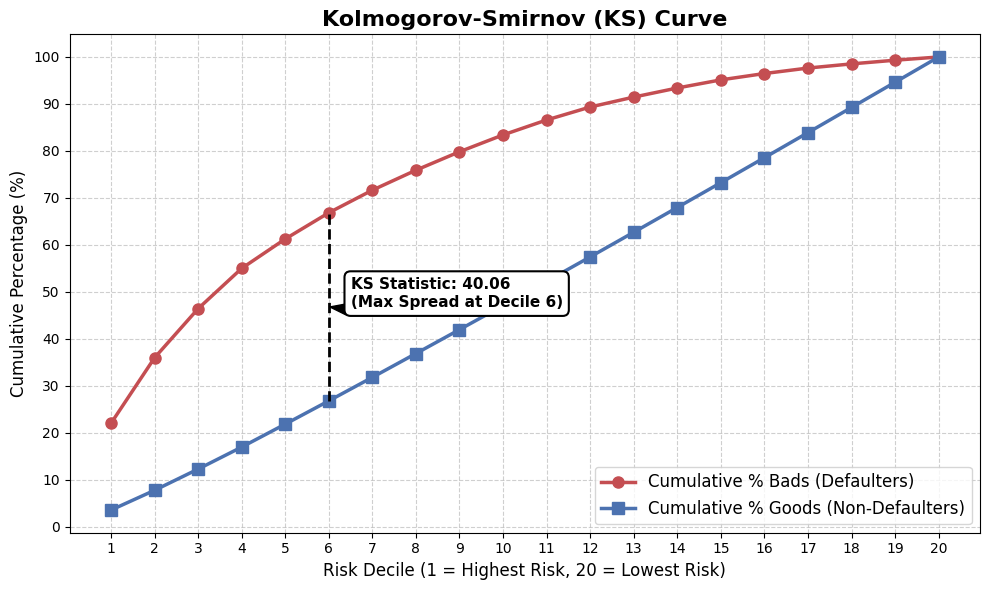

In [86]:
# ==============================================================================
# 4. PLOTTING THE KS CURVE
# ==============================================================================

# Extract the data from the ks_table we built in the previous step
deciles = ks_table.index.values
cum_bads = ks_table['Cum_Pct_Bads'] * 100
cum_goods = ks_table['Cum_Pct_Goods'] * 100
ks_spread = ks_table['KS_Spread']

# Find the decile where the KS statistic (maximum spread) occurs
ks_max_decile = ks_spread.idxmax()
ks_max_bad = cum_bads[ks_max_decile]
ks_max_good = cum_goods[ks_max_decile]
ks_stat_value = ks_spread[ks_max_decile]

# Create the plot
fig_ks, ax = plt.subplots(figsize=(10, 6))

# Plot the cumulative curves
ax.plot(deciles, cum_bads, marker='o', color='#C44E52', linewidth=2.5, markersize=8, label='Cumulative % Bads (Defaulters)')
ax.plot(deciles, cum_goods, marker='s', color='#4C72B0', linewidth=2.5, markersize=8, label='Cumulative % Goods (Non-Defaulters)')

# Draw a vertical dashed line to highlight the KS gap
ax.vlines(x=ks_max_decile, ymin=ks_max_good, ymax=ks_max_bad, color='black', 
          linestyle='--', linewidth=2, zorder=3)

# Add an annotation pointing to the KS gap
ax.annotate(f'KS Statistic: {ks_stat_value:.2f}\n(Max Spread at Decile {ks_max_decile})', 
            xy=(ks_max_decile, (ks_max_bad + ks_max_good) / 2), 
            xytext=(ks_max_decile + 0.5, (ks_max_bad + ks_max_good) / 2),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
            fontsize=11, fontweight='bold', 
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="black", lw=1.5))

# Formatting the chart
ax.set_title('Kolmogorov-Smirnov (KS) Curve', fontsize=16, fontweight='bold')
ax.set_xlabel('Risk Decile (1 = Highest Risk, 20 = Lowest Risk)', fontsize=12)
ax.set_ylabel('Cumulative Percentage (%)', fontsize=12)

# Ensure X-axis only shows whole numbers 1 through 20
ax.set_xticks(deciles)
# Ensure Y-axis goes from 0 to 100 with steps of 10
ax.set_yticks(np.arange(0, 110, 10))

ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='lower right', fontsize=12)

plt.tight_layout()
fig_ks.savefig(os.path.join(MODEL_OUTPUT_DIR, 'KS_Curve.png'), dpi=150, bbox_inches='tight')
plt.show()

### 7.d Data Drift - test vs train (PSI test)

In [ ]:
def calculate_psi(grp1, grp2, n_bins=10, min_bin_edge = 0, max_bin_edge = 1):
    """
    Calculates the Population Stability Index (PSI) between training (expected)
    and validation/production (actual) predicted probabilities.
    """
    # 1. Determine quantile bin edges using the grp1 dataset
    _, bin_edges = pd.qcut(grp1, n_bins, retbins=True)
    
    # Adjust outer edges slightly to prevent out-of-bounds errors
    bin_edges[0] = min_bin_edge
    bin_edges[-1] = max_bin_edge
    
    # 2. Count how many applicants fall into each bin for both datasets
    grp1_counts = np.histogram(grp1, bins=bin_edges)[0]
    grp2_counts = np.histogram(grp2, bins=bin_edges)[0]
    
    # 3. Convert counts to percentages
    grp1_pct = grp1_counts / len(grp1)
    grp2_pct = grp2_counts / len(grp2)
    
    # 4. Handle any zero-count bins to avoid division-by-zero/log errors
    grp1_pct = np.where(grp1_pct == 0, 1e-4, grp1_pct)
    grp2_pct = np.where(grp2_pct == 0, 1e-4, grp2_pct)
    
    # 5. Calculate PSI for each bin and sum them up
    # Formula: (Actual% - Expected%) * ln(Actual% / Expected%)
    bin_psi = (grp2_pct - grp1_pct) * np.log(grp2_pct / grp1_pct)
    total_psi = np.sum(bin_psi)

    psi_df = pd.DataFrame({
        'Bin': [f'Bin {i+1}' for i in range(n_bins)],
        'Bin_Range': [f"{bin_edges[i]:.4f} - {bin_edges[i+1]:.4f}" for i in range(n_bins)],
        'Expected_Pct': grp1_pct,
        'Actual_Pct': grp2_pct,
        'PSI_Contribution': bin_psi
    })

    return total_psi, psi_df

# --- Example Usage ---
# psi_value = calculate_psi(y_train_proba, y_val_proba, n_bins=10)
# print(f"Population Stability Index (PSI): {psi_value:.4f}")

In [ ]:
psi_value, psi_df = calculate_psi(train_df.predicted_proba, test_df.predicted_proba, n_bins=10, min_bin_edge=0, max_bin_edge=1)
psi_df.to_excel(os.path.join(MODEL_OUTPUT_DIR, 'psi_table.xlsx'), index=False)

print("="*40)
print(f"Train vs. Test PSI: {psi_value:.4f}")
print("="*40)

if psi_value < 0.10:
    print("🟢 PASS: The test population is highly stable and representative of the training data.")
elif psi_value < 0.25:
    print("🟡 WARNING: Moderate shift detected. Check your data split for potential bias.")
else:
    print("🔴 FAIL: Significant distribution shift! Your validation set is fundamentally different from your training set.")

Train vs. Test PSI: 0.0001
🟢 PASS: The test population is highly stable and representative of the training data.


## 8. MLflow Tracking & Model Registration

Logs hyperparameters, metrics, plots, and a production-ready `pyfunc` wrapper that
handles categorical dtype reconstruction at inference time.

In [88]:
if ENABLE_MLFLOW:
    import mlflow
    import mlflow.pyfunc
    from mlflow.models import infer_signature
    from mlflow.tracking import MlflowClient

    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
    mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

    input_example  = X_val.head(3)
    output_example = final_model.predict(input_example)
    model_signature = infer_signature(input_example, output_example)

    print(f"MLflow tracking URI : {MLFLOW_TRACKING_URI}")
    print(f"MLflow experiment   : {MLFLOW_EXPERIMENT_NAME}")
else:
    print("ENABLE_MLFLOW=False — skipping MLflow tracking section.")

MLflow tracking URI : file:a:/Dominic/My Projects/Home Credit/data/mlruns
MLflow experiment   : Home_Credit_Default_Risk


a:\Dominic\My Projects\Home Credit\project_env\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


In [89]:
if ENABLE_MLFLOW:

    class LightGBMProductionWrapper(mlflow.pyfunc.PythonModel):
        """
        Wraps the trained LightGBM model so the MLflow pyfunc API can serve it.
        Reconstructs pandas 'category' dtype for categorical columns, since this
        information is lost when the model is served over JSON.
        """
        def __init__(self, trained_model, categorical_features):
            self.trained_model = trained_model
            self.categorical_features = categorical_features

        def predict(self, context, model_input):
            processed_df = model_input.copy()
            for col in self.categorical_features:
                if col in processed_df.columns:
                    processed_df[col] = processed_df[col].astype('category')
            probabilities = self.trained_model.predict_proba(processed_df)
            return probabilities[:, 1].tolist()

    cat_features = [col for col in X_val.columns if X_val[col].dtype.name == 'category']
    wrapped_production_model = LightGBMProductionWrapper(
        trained_model=final_model,
        categorical_features=cat_features,
    )
    print(f"Wrapped model with {len(cat_features)} categorical features.")

Wrapped model with 6 categorical features.


a:\Dominic\My Projects\Home Credit\project_env\Lib\site-packages\mlflow\pyfunc\utils\data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


In [90]:
if ENABLE_MLFLOW:

    with mlflow.start_run(run_name="LGBM_Custom_Wrapper_Deployment") as run:
        mlflow.log_params(resolved_best)
        mlflow.log_param("device", "cpu")
        mlflow.log_param("random_state", RANDOM_STATE)
        mlflow.log_param("test_size", TEST_SIZE)

        mlflow.log_metric("val_auc", val_auc)
        mlflow.log_metric("val_f1_score", best_f1_score)
        mlflow.log_metric("val_threshold", best_threshold)
        mlflow.log_metric("val_log_loss", log_loss(y_val, y_val_proba))
        # log BOTH classes explicitly — class '1' (default) is the metric of interest
        mlflow.log_metric("val_precision_class1", report_df.loc['1', 'precision'])
        mlflow.log_metric("val_recall_class1",    report_df.loc['1', 'recall'])
        mlflow.log_metric("val_precision_class0", report_df.loc['0', 'precision'])
        mlflow.log_metric("val_recall_class0",    report_df.loc['0', 'recall'])
        mlflow.log_metric("ks_statistic", ks_statistic)
        mlflow.log_metric("Calibration_Error", ece)

        mlflow.pyfunc.log_model(
            artifact_path="lightgbm_model",
            python_model=wrapped_production_model,
            registered_model_name=MLFLOW_REGISTERED_MODEL_NAME,
            signature=model_signature,
        )
        mlflow.log_figure(figure=fig_roc, artifact_file="plots/ModelEvaluationCurves.png")
        mlflow.log_figure(figure=fig_cal, artifact_file="plots/CalibrationCurves.png")
        mlflow.log_figure(figure=fig_ks, artifact_file="plots/KS_Curve.png")

        mlflow.log_text(text=report_text, artifact_file="metadata/classification_report.txt")
        mlflow.log_artifact(
            local_path=os.path.join(MODEL_OUTPUT_DIR, 'lgbm_feature_importance.xlsx'),
            artifact_path="metadata",
        )
        mlflow.log_artifact(
            local_path=os.path.join(MODEL_OUTPUT_DIR, 'quantile_binning_table.xlsx'),
            artifact_path="metadata",
        )
        mlflow.log_artifact(
            local_path=os.path.join(MODEL_OUTPUT_DIR, 'uniform_binning_table.xlsx'),
            artifact_path="metadata",
        )
        mlflow.log_artifact(
            local_path=os.path.join(MODEL_OUTPUT_DIR, 'ks_table.xlsx'),
            artifact_path="metadata",
        )
        print(f"Success! Run ID: {run.info.run_id}")

2026/07/13 23:41:40 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/07/13 23:41:40 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.
a:\Dominic\My Projects\Home Credit\project_env\Lib\site-packages\mlflow\pyfunc\__init__.py:3343: UserWarning: An input example was not provided when logging the model. To ensure the model signature functions correctly, specify the `input_example` parameter. See https://mlflow.org/docs/latest/model/signatures.html#model-input-example for more details about the benefits of using input_example.
  color_warning(
Registered model 'HomeCredit_Scorecard_Model' already exists. Creating a new version of this model...


Success! Run ID: b51508625e6441d2a6b37421541c1cde


In [91]:
if ENABLE_MLFLOW:

    # FIX: client instantiated BEFORE use (original called it one cell too early)
    client = MlflowClient(tracking_uri=MLFLOW_TRACKING_URI)

    latest_versions = client.get_latest_versions(name=MLFLOW_REGISTERED_MODEL_NAME)
    newest_version = max(latest_versions, key=lambda v: int(v.version))

    # client.set_registered_model_alias(
    #     name=MLFLOW_REGISTERED_MODEL_NAME,
    #     alias="prod",
    #     version=newest_version.version,
    # )

    # Promotion to prod is a manual, deliberate gate — assign the alias yourself
    # in the MLflow UI (Models -> HomeCredit_Scorecard_Model -> select a version
    # -> Add alias -> 'prod') after reviewing this run's metrics.
    print(f"Registered model version: {newest_version.version}")
    print(f"Run ID for this version : {newest_version.run_id}")
    print("\n'prod' alias not set automatically — assign it manually in the MLflow UI "
          "once you've reviewed this run.")

Registered model version: 2
Run ID for this version : b51508625e6441d2a6b37421541c1cde

'prod' alias not set automatically — assign it manually in the MLflow UI once you've reviewed this run.


C:\Users\domjo\AppData\Local\Temp\ipykernel_33232\505235479.py:6: FutureWarning: ``mlflow.tracking.client.MlflowClient.get_latest_versions`` is deprecated since 2.9.0. Model registry stages will be removed in a future major release. To learn more about the deprecation of model registry stages, see our migration guide here: https://mlflow.org/docs/latest/model-registry.html#migrating-from-stages
  latest_versions = client.get_latest_versions(name=MLFLOW_REGISTERED_MODEL_NAME)


### Viewing the MLflow UI

`mlflow ui` is a **shell command**, not Python — it must be run in a terminal, not
executed as a notebook cell (the original notebook had this as a bare code cell,
which raises a `SyntaxError` if run).

From a terminal, with the project root as the working directory:

```bash
mlflow ui --backend-store-uri "file:./data/mlruns"
```

## 9. Cleanup

In [92]:
del X_train, X_val, y_train, y_val, X, y, model_dataset
import gc; gc.collect()
print("All DataFrames released.")

All DataFrames released.
